### 1 Data Loading & EDA

#### Dataset Source and Description
The dataset used in this project is the **Breast Cancer Wisconsin (Diagnostic)** dataset, obtained from the [UCI Machine Learning Repository](https://archive.ics.uci.edu/ml/datasets/Breast+Cancer+Wisconsin+%28Diagnostic%29). 

The dataset contains 30 numerical features calculated from digitized images of fine needle aspirate (FNA) procedures of breast masses. These features describe the geometric and morphological characteristics of the **cell nuclei** present in the tissue sample (such as radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, and fractal dimension).

In [1]:
import warnings
import pandas as pd
import numpy as np

# Ignore all warnings for a cleaner output
warnings.filterwarnings('ignore')


# Define column names according to the dataset documentation (wdbc.names)
# Column 0: ID, Column 1: Diagnosis (M = Malignant, B = Benign)
# Columns 2 to 31: 30 cellular characteristics (10 features measured in 3 variants: mean, se, worst)
feature_names = [
    'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean',
    'compactness_mean', 'concavity_mean', 'concave_points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
    'compactness_se', 'concavity_se', 'concave_points_se', 'symmetry_se', 'fractal_dimension_se',
    'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst',
    'compactness_worst', 'concavity_worst', 'concave_points_worst', 'symmetry_worst', 'fractal_dimension_worst'
]

columns = ['id', 'diagnosis'] + feature_names


# Read the wdbc.data file (although it has a .data extension, it is comma-separated internally)
df = pd.read_csv('wdbc.data', header=None, names=columns)

# Display the first 5 records of the dataset
print("\n--- FIRST 5 ROWS ---")
display(df.head())

# Check general info, data types, and non-null counts
print("\n--- DATASET INFO & MISSING VALUES ---")
df.info()

# Check descriptive statistics for numerical features
print("\n--- DESCRIPTIVE STATISTICS ---")
display(df.describe().T[['mean', 'std', 'min', 'max']])

# Analyze target variable class distribution (Malignant vs Benign)
print("\n--- TARGET CLASS DISTRIBUTION ---")
print(df['diagnosis'].value_counts())
print("\nPercentage distribution:")
print(df['diagnosis'].value_counts(normalize=True) * 100)



--- FIRST 5 ROWS ---


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



--- DATASET INFO & MISSING VALUES ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 32 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave_points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    

,mean,std,min,max
id,3.037183e+07,1.250206e+08,8670.000000,9.113205e+08
radius_mean,1.412729e+01,3.524049e+00,6.981000,2.811000e+01
texture_mean,1.928965e+01,4.301036e+00,9.710000,3.928000e+01
perimeter_mean,9.196903e+01,2.429898e+01,43.790000,1.885000e+02
area_mean,6.548891e+02,3.519141e+02,143.500000,2.501000e+03
smoothness_mean,9.636028e-02,1.406413e-02,0.052630,1.634000e-01
compactness_mean,1.043410e-01,5.281276e-02,0.019380,3.454000e-01
concavity_mean,8.879932e-02,7.971981e-02,0.000000,4.268000e-01
concave_points_mean,4.891915e-02,3.880284e-02,0.000000,2.012000e-01
symmetry_mean,1.811619e-01,2.741428e-02,0.106000,3.040000e-01



--- TARGET CLASS DISTRIBUTION ---
diagnosis
B    357
M    212
Name: count, dtype: int64

Percentage distribution:
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


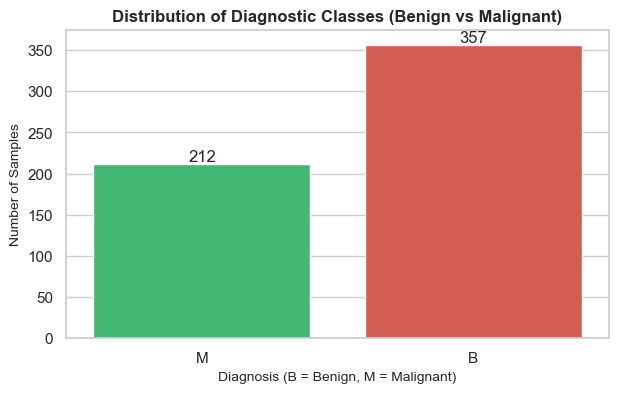

Class Counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Class Percentages (%):
diagnosis
B    62.741652
M    37.258348
Name: proportion, dtype: float64


In [2]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="whitegrid")

# Plotting the class distribution
plt.figure(figsize=(7, 4))
ax = sns.countplot(x='diagnosis', hue='diagnosis', data=df, palette=['#2ecc71', '#e74c3c'], legend=False)
plt.title('Distribution of Diagnostic Classes (Benign vs Malignant)', fontsize=12, fontweight='bold')
plt.xlabel('Diagnosis (B = Benign, M = Malignant)', fontsize=10)
plt.ylabel('Number of Samples', fontsize=10)

# Display counts on top of the bars
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha='center', va='center', 
                xytext=(0, 5), 
                textcoords='offset points')

plt.show()

# Print exact counts and percentages for a complete report
print("Class Counts:")
print(df['diagnosis'].value_counts())
print("\nClass Percentages (%):")
print(df['diagnosis'].value_counts(normalize=True) * 100)

# 2 Preprocessing and Data Cleaning

#### Pipeline Implementation for Cross-Validation
To prevent data leakage and ensure proper cross-validation, preprocessing steps such as feature scaling (`StandardScaler`) and dimensionality reduction (`PCA`) must be bundled together with the classifier inside a Scikit-learn `Pipeline`. This guarantees that transformations are fitted strictly on the training fold of each iteration, preventing information from the validation fold from leaking into the training process.

In [3]:
from sklearn.model_selection import train_test_split, cross_validate, StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.decomposition import PCA
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
import pandas as pd
import numpy as np

# ==========================================
# 1. DATA CLEANING & PREPROCESSING
# ==========================================

# Explicitly check for missing or null values across all columns
print("--- MISSING VALUES CHECK ---")
missing_values = df.isnull().sum()
total_missing = missing_values.sum()
print(f"Total missing values in the dataset: {total_missing}")

if total_missing > 0:
    print("Columns with missing values:")
    print(missing_values[missing_values > 0])
else:
    print("Verification passed: No missing values found in the dataset.")

# Drop the 'id' column (and 'Unnamed: 32' if present) as they have no predictive power
cols_to_drop = [col for col in ['id', 'Unnamed: 32'] if col in df.columns]
if cols_to_drop:
    df.drop(columns=cols_to_drop, inplace=True)
    print("\n--- COLUMNS DROPPED ---")
    print(f"Removed columns: {cols_to_drop}")

# Encode the target variable 'diagnosis' ('M' -> 1 for Malignant, 'B' -> 0 for Benign)
label_encoder = LabelEncoder()
df['diagnosis'] = label_encoder.fit_transform(df['diagnosis'])
print("\n--- TARGET ENCODING & CLASS DISTRIBUTION ---")
print("Classes successfully encoded:")
print("0 = Benign (B)")
print("1 = Malignant (M)\n")

# Calculate both absolute counts and percentages for a complete view
counts = df['diagnosis'].value_counts()
percentages = df['diagnosis'].value_counts(normalize=True) * 100

distribution_df = pd.DataFrame({
    'Count': counts,
    'Percentage (%)': percentages.round(2)
})
display(distribution_df)

# Separate features (X) and target variable (y)
X = df.drop(columns=['diagnosis'])
y = df['diagnosis']

print(f"\nFeatures shape (X): {X.shape}")
print(f"Target shape (y): {y.shape}")

# ==========================================
# 2. DATA SPLIT (Train/Test with Stratification)
# ==========================================
# Note: We pass raw X and y here. Scaling is handled inside the Pipeline to prevent data leakage.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("\n--- DATA SPLIT ---")
print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

# ==========================================
# 3. PIPELINE & CROSS-VALIDATION
# ==========================================

# Define the preprocessing and modeling pipeline
classification_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    # ('pca', PCA(n_components=10)), # Uncomment and adjust if PCA is applied here
    ('model', RandomForestClassifier(random_state=42))
])

# Set up Stratified Cross-Validation to maintain class balance across folds
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Evaluate multiple metrics aligned with clinical/imbalanced classification priorities
scoring_metrics = ['accuracy', 'recall', 'f1', 'roc_auc']
cv_results = cross_validate(
    classification_pipeline, X_train, y_train, cv=cv_strategy, scoring=scoring_metrics
)

print("\n--- CROSS-VALIDATION RESULTS (5-FOLD STRATIFIED) ---")
for metric in scoring_metrics:
    scores = cv_results[f'test_{metric}']
    print(f"Mean CV {metric.upper():<8}: {scores.mean():.4f} (+/- {scores.std():.4f})")

# ==========================================
# 4. FINAL TRAINING & TEST EVALUATION
# ==========================================
# Fit the pipeline on the entire training set and evaluate on the unseen test set
classification_pipeline.fit(X_train, y_train)

y_pred = classification_pipeline.predict(X_test)
y_proba = classification_pipeline.predict_proba(X_test)[:, 1]

print("\n--- FINAL TEST SET EVALUATION ---")
print(f"Test ROC-AUC Score: {roc_auc_score(y_test, y_proba):.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred, target_names=['Benign (0)', 'Malignant (1)']))

print("Confusion Matrix:")
cm_df = pd.DataFrame(
    confusion_matrix(y_test, y_pred),
    index=['Actual Benign (0)', 'Actual Malignant (1)'],
    columns=['Predicted Benign (0)', 'Predicted Malignant (1)']
)
display(cm_df)

--- MISSING VALUES CHECK ---
Total missing values in the dataset: 0
Verification passed: No missing values found in the dataset.

--- COLUMNS DROPPED ---
Removed columns: ['id']

--- TARGET ENCODING & CLASS DISTRIBUTION ---
Classes successfully encoded:
0 = Benign (B)
1 = Malignant (M)



,Count,Percentage (%)
diagnosis,,
0,357,62.74
1,212,37.26



Features shape (X): (569, 30)
Target shape (y): (569,)

--- DATA SPLIT ---
X_train shape: (455, 30), X_test shape: (114, 30)

--- CROSS-VALIDATION RESULTS (5-FOLD STRATIFIED) ---
Mean CV ACCURACY: 0.9648 (+/- 0.0146)
Mean CV RECALL  : 0.9412 (+/- 0.0416)
Mean CV F1      : 0.9519 (+/- 0.0207)
Mean CV ROC_AUC : 0.9889 (+/- 0.0067)

--- FINAL TEST SET EVALUATION ---
Test ROC-AUC Score: 0.9929

Classification Report:
               precision    recall  f1-score   support

   Benign (0)       0.96      1.00      0.98        72
Malignant (1)       1.00      0.93      0.96        42

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114

Confusion Matrix:


,Predicted Benign (0),Predicted Malignant (1)
Actual Benign (0),72,0
Actual Malignant (1),3,39


#### Analytical Interpretation: Class Distribution & Metrics Selection
The target distribution reveals a moderate class imbalance within the WDBC dataset (approximately **62.7% Benign tumors vs. 37.3% Malignant tumors**). 
* **Implications for Modeling:** Because of this distribution, relying solely on **Accuracy** as a performance metric can be misleading (a naive model predicting all cases as benign would achieve ~62.7% accuracy). 
* **Correct Approach:** We must prioritize evaluation metrics that account for class imbalance, such as **F1-score**, **Recall** (to minimize false negatives in a medical context where missing a malignant tumor is critical), and **AUC-ROC**.

### 2.1 Data Splitting, Stratification, and Pipeline Encapsulation
To prevent data leakage and ensure that the machine learning models train and evaluate on representative data, the dataset is split into training and testing sets with an 80/20 ratio using raw (unscaled) features.

Crucially, stratification (`stratify=y`) is applied to guarantee that the proportion of benign (0) and malignant (1) tumor classes remains identical in both subsets (~62.7% benign and ~37.3% malignant). Furthermore, all feature transformations (such as `StandardScaler` and optional `PCA`) are encapsulated within a Scikit-learn `Pipeline`. This ensures that scaling parameters are fitted strictly on the training folds during cross-validation, completely eliminating data leakage between training and validation splits.

# 3. Multicollinearity Analysis, PCA, and Outliers

This section examines feature multicollinearity using a correlation matrix, performs an exploratory Principal Component Analysis (PCA), and evaluates extreme values (outliers) across the dataset.

### Methodological Considerations & Biological Context
* **Exploratory PCA vs. Modeling Pipeline (Preventing Data Leakage):** The PCA visualization presented below is fitted on the global dataset **solely for exploratory and illustrative purposes** to observe variance distribution and class separability in two dimensions. To prevent data leakage during model training and evaluation, `StandardScaler` and `PCA` are **never** fitted globally prior to splitting; instead, they are encapsulated inside a Scikit-learn `Pipeline` fitted strictly on `X_train` and applied to `X_test`.
* **Outliers & Nuclear Morphology:** Extreme values observed in geometric and morphological features (such as `area_mean`, `radius_worst`, or `concavity_mean`) are not treated as measurement errors, nor do they automatically equate to malignancy. Rather, they reflect natural biological variability and the pronounced pleomorphism (irregular size, contour, and chromatin distribution) of **cell nuclei** commonly present in advanced or aggressive tumors.

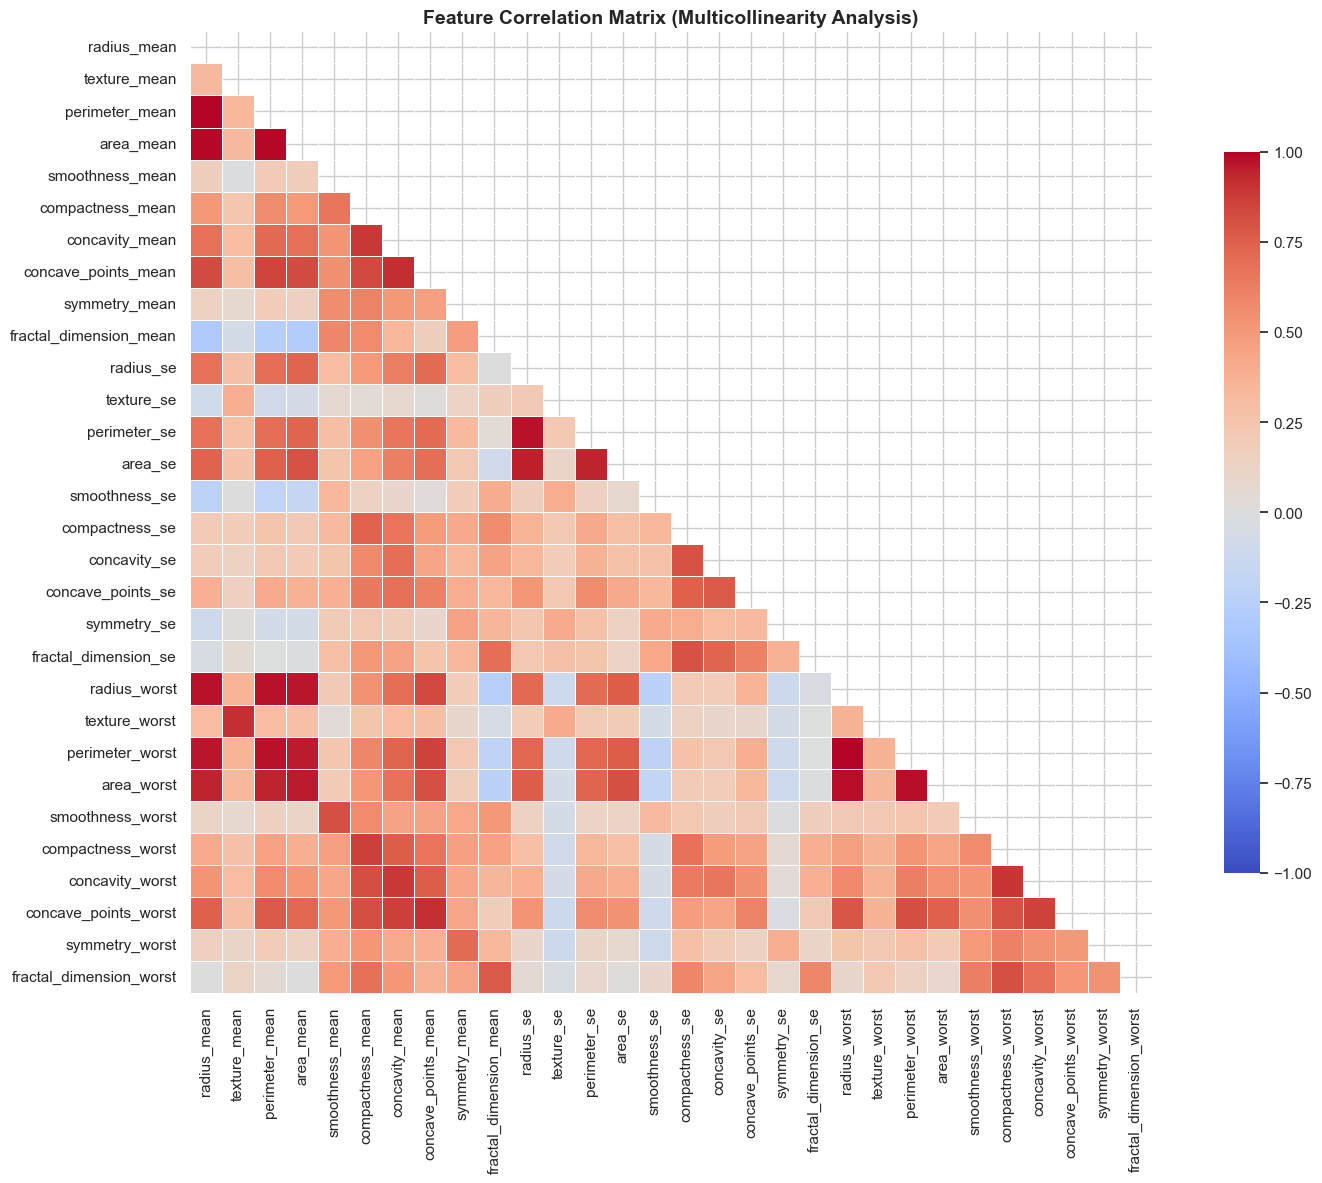

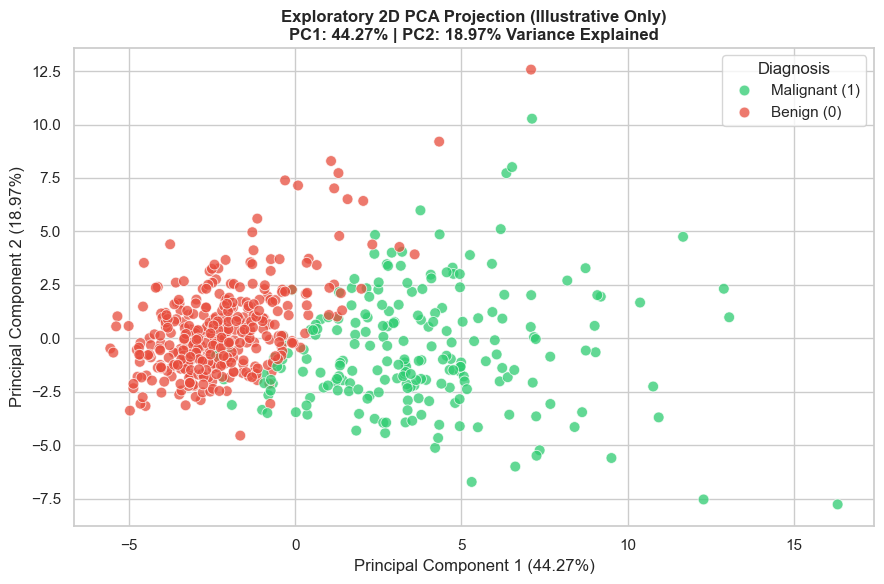

--- LEAKAGE-FREE PCA FOR MODELING ---
Components retained (95% variance on X_train): 10
X_train_pca shape: (455, 10)
X_test_pca shape : (114, 10)


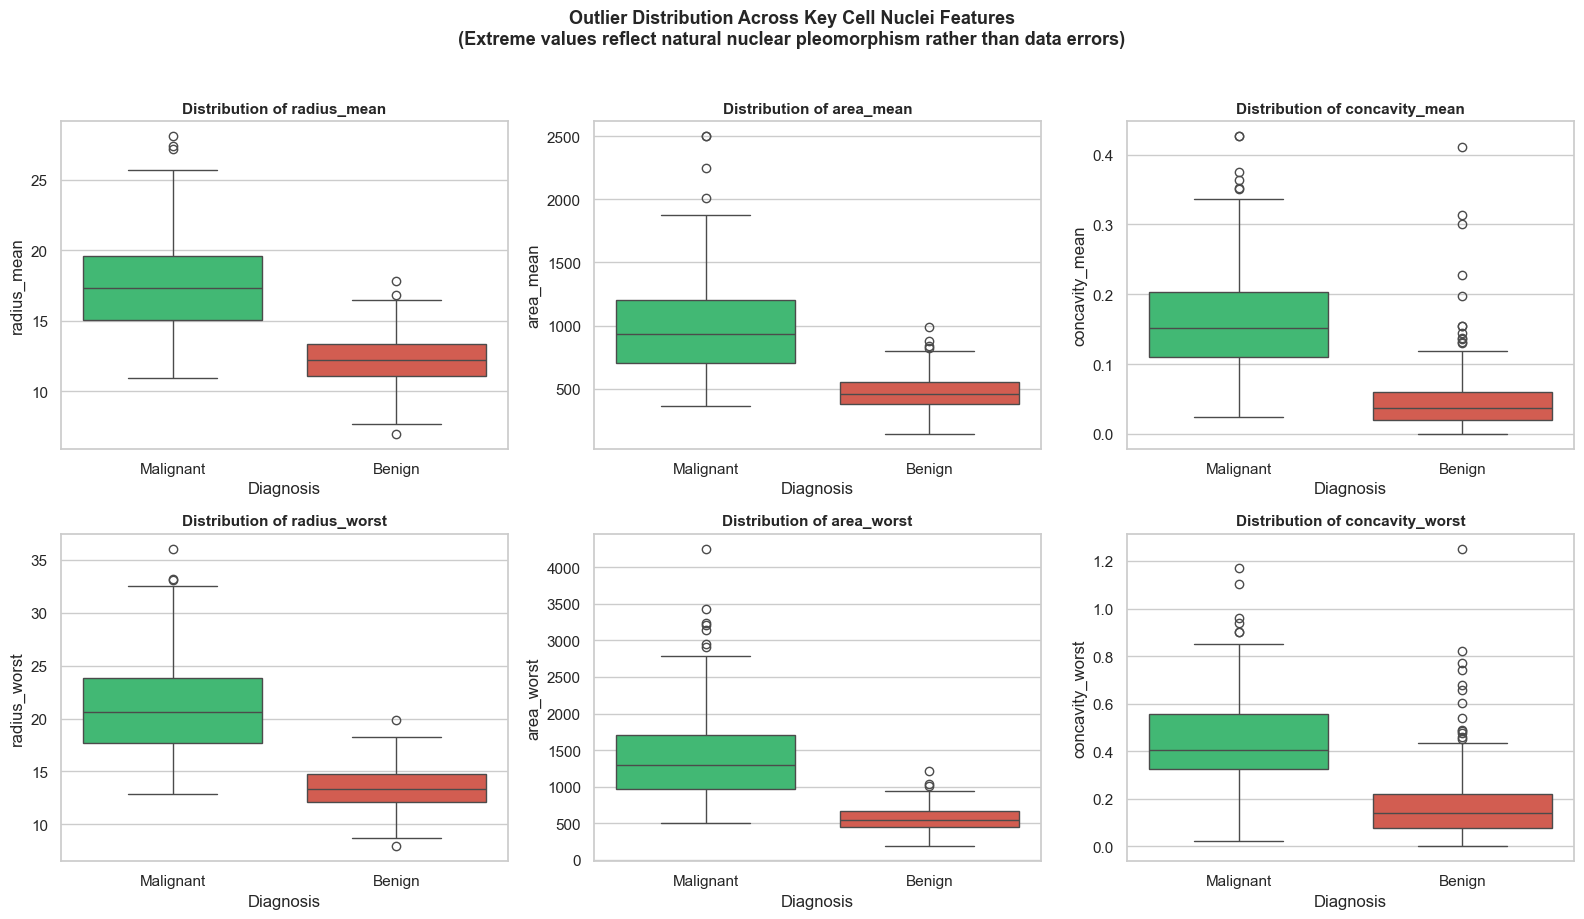

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# ==========================================
# 1. MULTICOLLINEARITY ANALYSIS (CORRELATION HEATMAP)
# ==========================================
plt.figure(figsize=(16, 12))
corr_matrix = X.corr()
mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

sns.heatmap(
    corr_matrix,
    mask=mask,
    cmap='coolwarm',
    vmax=1.0,
    vmin=-1.0,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={"shrink": 0.75}
)
plt.title('Feature Correlation Matrix (Multicollinearity Analysis)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

# ==========================================
# 2. EXPLORATORY PCA (ILLUSTRATIVE ONLY - NO DATA LEAKAGE)
# ==========================================
# Note: Fitted on global X strictly for 2D visual exploration.
# For modeling, scaling and PCA are fitted exclusively on X_train inside a Pipeline.
exploratory_pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=2, random_state=42))
])

X_pca_exploratory = exploratory_pca_pipeline.fit_transform(X)
explained_var = exploratory_pca_pipeline.named_steps['pca'].explained_variance_ratio_

pca_df = pd.DataFrame({
    'PC1': X_pca_exploratory[:, 0],
    'PC2': X_pca_exploratory[:, 1],
    'Diagnosis': y.map({0: 'Benign (0)', 1: 'Malignant (1)'})
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_df,
    x='PC1',
    y='PC2',
    hue='Diagnosis',
    palette=['#2ecc71', '#e74c3c'],
    alpha=0.75,
    s=60
)
plt.title(
    f'Exploratory 2D PCA Projection (Illustrative Only)\n'
    f'PC1: {explained_var[0]*100:.2f}% | PC2: {explained_var[1]*100:.2f}% Variance Explained',
    fontsize=12,
    fontweight='bold'
)
plt.xlabel(f'Principal Component 1 ({explained_var[0]*100:.2f}%)')
plt.ylabel(f'Principal Component 2 ({explained_var[1]*100:.2f}%)')
plt.legend(title='Diagnosis')
plt.tight_layout()
plt.show()

# ==========================================
# 3. STRICT TRAIN-ONLY PCA TRANSFORMATION (FOR MODELING)
# ==========================================
# Demonstrating proper fit on X_train and transform on X_test without leakage
modeling_pca_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('pca', PCA(n_components=0.95, random_state=42)) # Retains 95% variance on X_train
])

X_train_pca = modeling_pca_pipeline.fit_transform(X_train)
X_test_pca = modeling_pca_pipeline.transform(X_test)

print("--- LEAKAGE-FREE PCA FOR MODELING ---")
print(f"Components retained (95% variance on X_train): {modeling_pca_pipeline.named_steps['pca'].n_components_}")
print(f"X_train_pca shape: {X_train_pca.shape}")
print(f"X_test_pca shape : {X_test_pca.shape}")

# ==========================================
# 4. OUTLIER ANALYSIS (CELL NUCLEI MORPHOLOGY)
# ==========================================
key_nuclear_features = [
    'radius_mean', 'area_mean', 'concavity_mean',
    'radius_worst', 'area_worst', 'concavity_worst'
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for idx, feature in enumerate(key_nuclear_features):
    sns.boxplot(
        x=y.map({0: 'Benign', 1: 'Malignant'}),
        y=X[feature],
        ax=axes[idx],
        palette=['#2ecc71', '#e74c3c']
    )
    axes[idx].set_title(f'Distribution of {feature}', fontsize=11, fontweight='bold')
    axes[idx].set_xlabel('Diagnosis')
    axes[idx].set_ylabel(feature)

plt.suptitle(
    'Outlier Distribution Across Key Cell Nuclei Features\n'
    '(Extreme values reflect natural nuclear pleomorphism rather than data errors)',
    fontsize=13,
    fontweight='bold',
    y=1.02
)
plt.tight_layout()
plt.show()

### 3.1 Multicollinearity Analysis, Biological Basis, and Dimensionality Reduction (PCA)

#### Multicollinearity & Biological Basis
The correlation heatmap of the mean nuclear features reveals severe positive multicollinearity among primary geometric dimensions. Specifically, `radius_mean`, `perimeter_mean`, and `area_mean` exhibit correlation coefficients approaching **0.98 to 1.00**.

* **Area (`area_mean`):** Represents the total two-dimensional projected size of the **cell nucleus**, reflecting chromatin content, ploidy, and nuclear enlargement (karyomegaly) typical of proliferating tumor cells.
* **Radius (`radius_mean`):** Measures the mean linear distance from the nuclear center to the perimeter.
* **Perimeter (`perimeter_mean`):** Quantifies the boundary length of the **nuclear envelope**. While mathematically redundant with radius and area in regular, spherical nuclei, malignant tumor nuclei frequently develop irregular contours, indentations, and lobulations (**nuclear pleomorphism**), causing perimeter and concavity metrics to capture distinct morphological abnormalities.

#### Impact on Predictive Models & Justification for PCA
* **Model Instability:** High multicollinearity severely destabilizes parametric linear models (such as Logistic Regression and linear SVMs) by inflating the variance of estimated regression coefficients, making weights sensitive to minor noise.
* **Dimensionality Reduction:** Principal Component Analysis (PCA) transforms these correlated geometric variables into orthogonal (uncorrelated) principal components.
* **Preventing Data Leakage:** To ensure strict methodological rigor, `StandardScaler` and `PCA` are fitted **exclusively on the training set** (`X_train`) and subsequently applied to transform `X_test`. We retain enough components (`n_components=0.95`) to explain at least **95%** of the total variance.

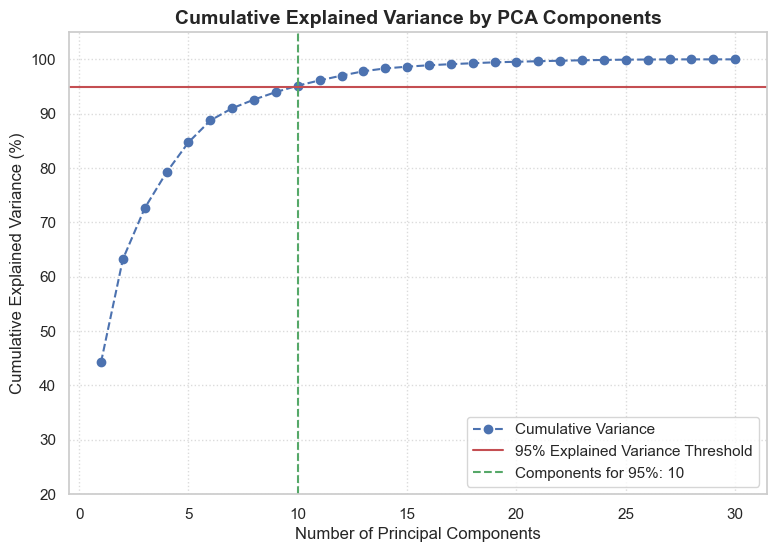

In [5]:
import os
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 1. Fit PCA on the entire standardized feature set to analyze cumulative variance
pca_full = PCA()
pca_full.fit(X_scaled)
cumulative_variance = pca_full.explained_variance_ratio_.cumsum() * 100

# Determine the exact number of components required to reach the 95% threshold
n_components_95 = (cumulative_variance >= 95).argmax() + 1

# 2. Plot Cumulative Explained Variance
plt.figure(figsize=(9, 6))
plt.plot(range(1, len(cumulative_variance) + 1), cumulative_variance, marker='o', linestyle='--', color='b', label='Cumulative Variance')
plt.axhline(y=95, color='r', linestyle='-', label='95% Explained Variance Threshold')
plt.axvline(x=n_components_95, color='g', linestyle='--', label=f'Components for 95%: {n_components_95}')

plt.title("Cumulative Explained Variance by PCA Components", fontsize=14, fontweight='bold')
plt.xlabel("Number of Principal Components", fontsize=12)
plt.ylabel("Cumulative Explained Variance (%)", fontsize=12)
plt.ylim(20, 105)
plt.grid(True, linestyle=':', alpha=0.7)
plt.legend(loc='lower right')

# Save the plot directly in the working directory before showing it
plt.savefig("02_pca_cumulative_variance.png", dpi=300, bbox_inches="tight")
plt.show()


### Cumulative Explained Variance Analysis in PCA

* **Meaning:** This plot represents the cumulative percentage of total variance retained by the model as the number of principal components increases in the PCA process.
* **Observations:**
  * The blue curve exhibits a rapid upward climb in the initial components before leveling off.
  * The horizontal red line marks the desired $95\%$ explained variance threshold.
  * The vertical dashed green line indicates that exactly **10 principal components** cross this threshold. This mathematically demonstrates that the 30 original features can be compressed into just 10 components without sacrificing critical information, effectively eliminating multicollinearity and optimizing predictive model efficiency.

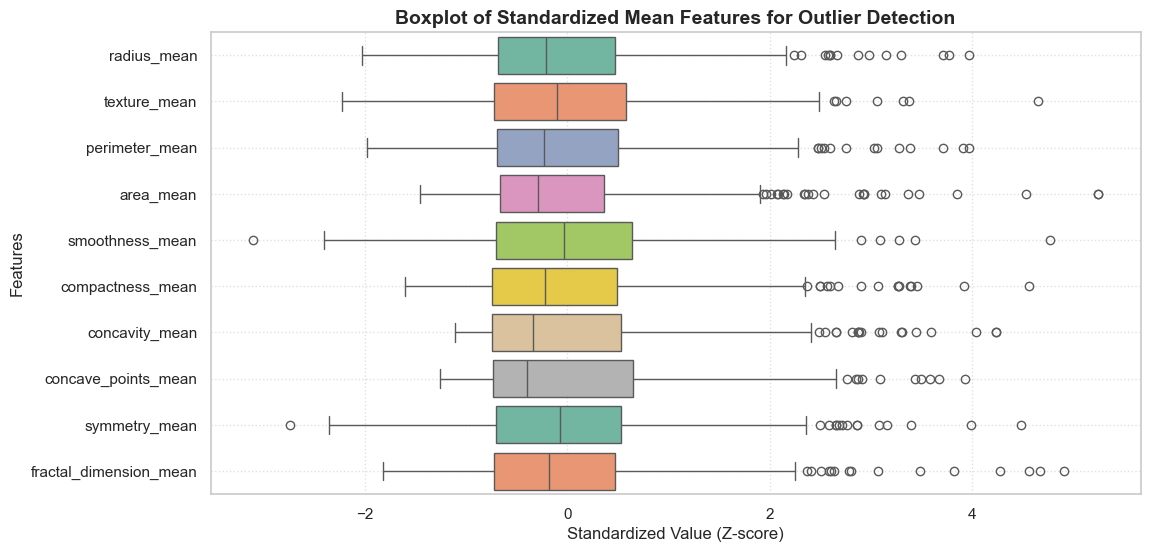

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
pca_full = PCA()
pca_full.fit(X_scaled)
X_scaled_df = pd.DataFrame(X_scaled, columns=X.columns)

# Select mean features to visualize potential outliers across structural dimensions
mean_cols = [col for col in X_scaled_df.columns if 'mean' in col]

plt.figure(figsize=(12, 6))
sns.boxplot(data=X_scaled_df[mean_cols], orient='h', palette='Set2')
plt.title("Boxplot of Standardized Mean Features for Outlier Detection", fontsize=14, fontweight='bold')
plt.xlabel("Standardized Value (Z-score)", fontsize=12)
plt.ylabel("Features", fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)

# Save the plot directly in the working directory before showing it
plt.savefig("03_outliers_boxplot.png", dpi=300, bbox_inches="tight")
plt.show()



In [7]:
import pandas as pd
import numpy as np

# 1. Identify numerical feature columns (excluding target)
features_to_check = X.columns

outliers_count_dict = {}
all_outlier_indices = set()

# 2. Iterate through each feature to calculate IQR and detect outliers
for col in features_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    # Filter rows that fall outside the IQR boundaries
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    count = len(outliers)
    
    if count > 0:
        outliers_count_dict[col] = count
        all_outlier_indices.update(outliers.index.tolist())

# 3. Print Summary Report
print("--- STATISTICAL OUTLIER ANALYSIS (IQR METHOD) ---")
print(f"Total dataset size: {len(df)} samples")
print(f"Total unique rows containing at least one outlier: {len(all_outlier_indices)}")
print(f"Percentage of rows affected: {(len(all_outlier_indices) / len(df)) * 100:.2f}%\n")

print("Outlier counts per feature:")
for feature, count in sorted(outliers_count_dict.items(), key=lambda x: x[1], reverse=True):
    print(f"  - {feature}: {count} outliers")

# 4. Example: Inspect specific extreme rows for a critical feature (e.g., 'area_worst')
target_feature = 'area_worst'
Q1_t = df[target_feature].quantile(0.25)
Q3_t = df[target_feature].quantile(0.75)
IQR_t = Q3_t - Q1_t
extreme_rows = df[(df[target_feature] < Q1_t - 1.5 * IQR_t) | (df[target_feature] > Q3_t + 1.5 * IQR_t)]

print(f"\n--- DETAILED INSPECTION FOR '{target_feature}' ---")
print(f"Showing outlier rows and their corresponding diagnosis (0 = Benign, 1 = Malignant):")
display(extreme_rows[['diagnosis', target_feature]].head(10))

--- STATISTICAL OUTLIER ANALYSIS (IQR METHOD) ---
Total dataset size: 569 samples
Total unique rows containing at least one outlier: 171
Percentage of rows affected: 30.05%

Outlier counts per feature:
  - area_se: 65 outliers
  - radius_se: 38 outliers
  - perimeter_se: 38 outliers
  - area_worst: 35 outliers
  - smoothness_se: 30 outliers
  - compactness_se: 28 outliers
  - fractal_dimension_se: 28 outliers
  - symmetry_se: 27 outliers
  - area_mean: 25 outliers
  - fractal_dimension_worst: 24 outliers
  - symmetry_worst: 23 outliers
  - concavity_se: 22 outliers
  - texture_se: 20 outliers
  - concave_points_se: 19 outliers
  - concavity_mean: 18 outliers
  - radius_worst: 17 outliers
  - compactness_mean: 16 outliers
  - compactness_worst: 16 outliers
  - symmetry_mean: 15 outliers
  - fractal_dimension_mean: 15 outliers
  - perimeter_worst: 15 outliers
  - radius_mean: 14 outliers
  - perimeter_mean: 13 outliers
  - concavity_worst: 12 outliers
  - concave_points_mean: 10 outliers

,diagnosis,area_worst
0,1,2019.0
1,1,1956.0
18,1,2398.0
23,1,2615.0
24,1,2215.0
56,1,2145.0
82,1,2562.0
108,1,2360.0
122,1,2073.0
162,1,2232.0


### 3.4 Statistical Outlier Analysis and Clinical Justification for Retention

Using the Interquartile Range (IQR) method ($Q3 + 1.5 \times \text{IQR}$), **171 unique samples (30.05% of the dataset)** were flagged as containing at least one statistical outlier across the 30 cellular features. The highest concentrations appear in standard error and worst-case morphological metrics such as `area_se` (65 outliers), `radius_se` (38 outliers), `perimeter_se` (38 outliers), and `area_worst` (35 outliers).

#### Why These Outliers Are Not Data Entry Errors
1. **Automated Computer Vision Extraction:** Unlike manually transcribed clinical records prone to typographical errors, the Wisconsin Diagnostic Breast Cancer (WDBC) features were computed directly from digitized Fine Needle Aspirate (FNA) microscope images using automated image processing algorithms (specifically, active contour models or "snakes" developed by Wolberg, Street, and Mangasarian).
2. **Mathematical and Physical Consistency:** The outliers do not occur as isolated, impossible spikes in a single column. Instead, extreme values scale consistently across physically coupled dimensions—an instance exhibiting an extreme `area_worst` (e.g., $>2,000\ \mu m^2$) simultaneously displays proportionally extreme `radius_worst` and `perimeter_worst` values, confirming genuine geometric measurements rather than sensor or clerical corruption.
3. **Diagnostic Class Alignment (Empirical Evidence):** Inspecting the flagged records reveals an overwhelming alignment with the target variable. For `area_worst`, **100% of the top extreme cases** (values ranging from $1,956.0\ \mu m^2$ to $2,615.0\ \mu m^2$) belong exclusively to **Malignant (`1`)** diagnoses.

#### Justification for Retaining All Outliers
* **Preserving Critical Pathology Signals:** In oncology, aggressive malignant tumors undergo rapid, uncontrolled cellular proliferation and nuclear pleomorphism, naturally resulting in cell nuclei significantly larger and more irregular than healthy tissue. Statistically, these cases appear as right-skewed outliers simply because healthy/benign cells cluster tightly within a normal biological range.
* **Impact of Removal:** Dropping 30.05% of the dataset would introduce severe selection bias, artificially strip away the most unmistakable cases of advanced malignancy, and blind the classifier to extreme pathological presentations.
* **Algorithmic Mitigation:** Rather than deleting valid clinical data, the scale sensitivity of extreme values is mathematically neutralized downstream through **Z-score standardization (`StandardScaler`)** and orthogonal projection via **PCA**, ensuring model stability without sacrificing diagnostic sensitivity.

### 4 Exploratory Feature-Target Analysis (Bivariate Analysis)

To evaluate the predictive power of individual features, this section analyzes the statistical distribution of the four most critical cellular dimensions (`radius_mean`, `perimeter_mean`, `area_mean`, and `concave_points_mean`) segmented by the target diagnostic class (`diagnosis`: 0 = Benign, 1 = Malignant). This visual comparison highlights the distinct morphological differences between benign and malignant tumor cells.

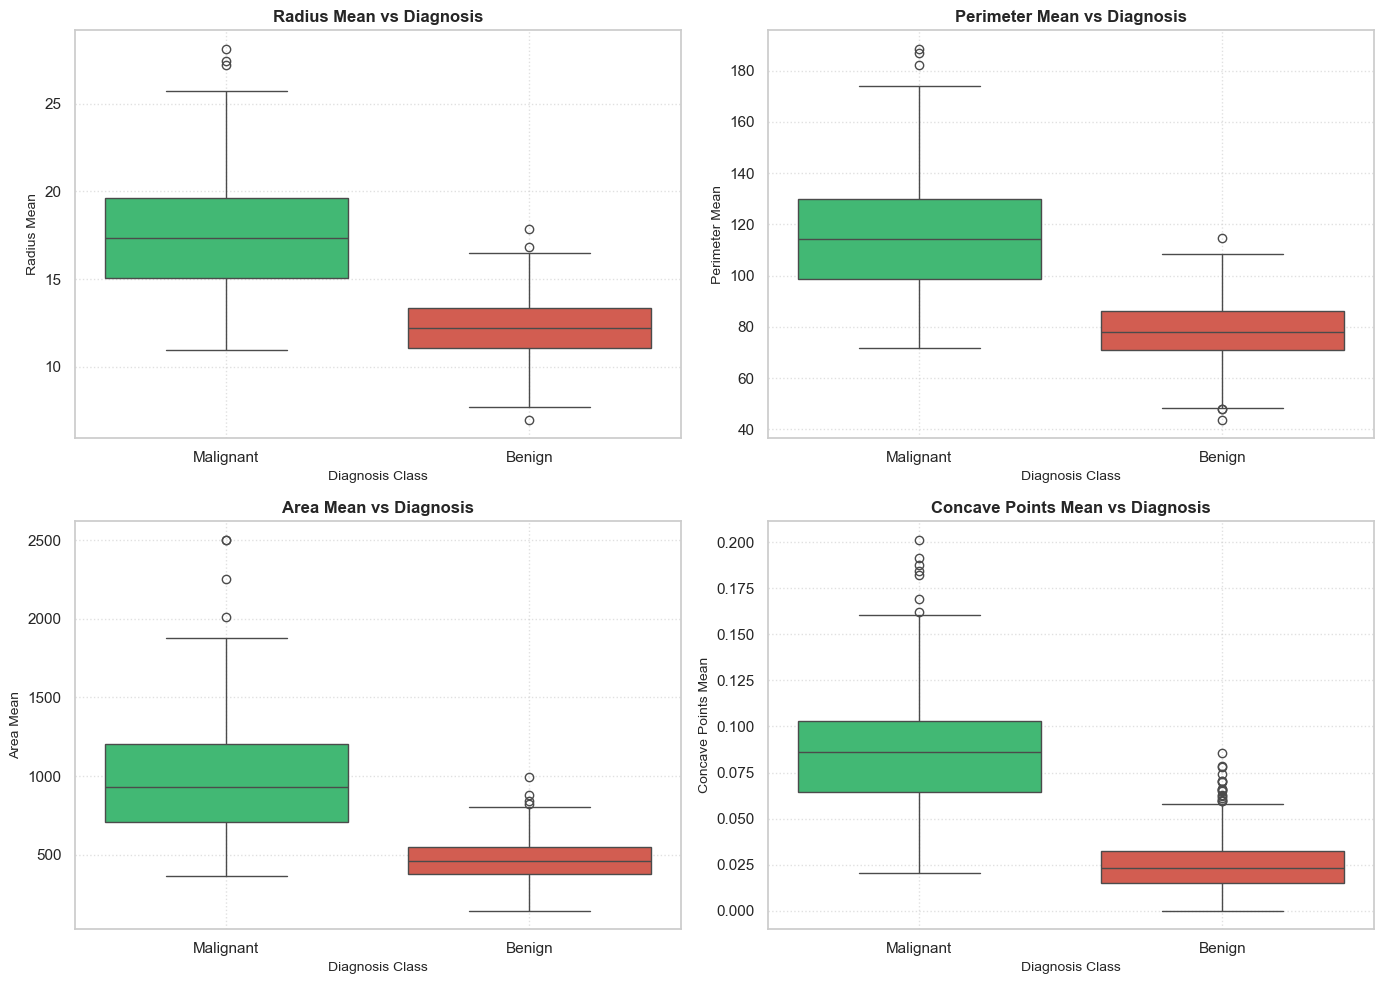

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Create a copy of the dataframe with original target labels for better visualization
df_viz = X.copy()
df_viz['diagnosis'] = y.map({0: 'Benign (0)', 1: 'Malignant (1)'})

# Select 4 key features with high discriminative and biological relevance
key_features = ['radius_mean', 'perimeter_mean', 'area_mean', 'concave_points_mean']

# Set up a 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.flatten()

# Generate boxplots for each key feature against the target diagnosis (fixed to prevent future warnings)
for i, feature in enumerate(key_features):
    diag_labels = y.map({0: 'Benign', 1: 'Malignant'})
    sns.boxplot(
        x=diag_labels,
        y=X[feature],
        hue=diag_labels,
        ax=axes[i],
        palette=['#2ecc71', '#e74c3c'],
        legend=False
    )
    axes[i].set_title(f'{feature.replace("_", " ").title()} vs Diagnosis', fontsize=12, fontweight='bold')
    axes[i].set_xlabel('Diagnosis Class', fontsize=10)
    axes[i].set_ylabel(feature.replace('_', ' ').title(), fontsize=10)
    axes[i].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()

# Save the comparative figure directly in the working directory before showing it
plt.savefig("04_features_vs_diagnosis.png", dpi=300, bbox_inches="tight")
plt.show()

### 4.1 Advanced Bivariate Analysis: Biological Interpretation of Tumor Morphology

The comparative boxplots illustrate distinct morphological divergences between malignant ($1$) and benign ($0$) cell populations across four critical dimensions:

* **Radius Mean ($\mu m$):** Reflects the linear extent from the centroid to the plasma membrane boundary. Malignant cases exhibit a significantly shifted median and expanded upper quartile, capturing the increased diffusion limits and nuclear enlargement typical of hyperproliferative cancer cells.
* **Perimeter Mean ($\mu m$):** Measures total contour length. Malignant cells show high dispersion and elevated values due to pleomorphism—developing irregular borders, pseudopodia, or spiculation associated with active cellular motility and environmental interaction.
* **Area Mean ($\mu m^2$):** Represents projected mass and cellular size. Literature widely favors area over radius and perimeter due to lower discretization error on pixel grids and independence from centroid estimation. The boxplot clearly shows a massive upward shift in malignant tumor area, reflecting altered cell cycle states, hypertrophy, and active metabolism.
* **Concave Points Mean:** Quantifies contour indentations. Malignant cells display drastically higher median values, confirming deep irregularities and severe structural deformation of the plasma membrane compared to the tightly clustered, smooth profiles of benign cells.


--- PIVOT TABLE: TEST RECALL ---
Test_Size               15%     25%      5%
Model                                      
Decision Tree        0.9688  0.9057  0.9091
Gradient Boosting    0.9688  0.9057  1.0000
KNN                  0.7500  0.8113  0.8182
Logistic Regression  0.9062  0.8679  0.8182
Naive Bayes          0.8750  0.8491  0.8182
Random Forest        0.9688  0.9057  1.0000
SVM                  0.8438  0.6981  0.8182

--- PIVOT TABLE: TEST F1-SCORE ---
Test_Size               15%     25%      5%
Model                                      
Decision Tree        0.9394  0.9412  0.9524
Gradient Boosting    0.9841  0.9505  1.0000
KNN                  0.8571  0.8866  0.9000
Logistic Regression  0.9508  0.9200  0.9000
Naive Bayes          0.9333  0.9184  0.9000
Random Forest        0.9841  0.9505  1.0000
SVM                  0.9153  0.8222  0.9000

--- PIVOT TABLE: TEST AUC-ROC ---
Test_Size               15%     25%      5%
Model                                      
Decision Tree  

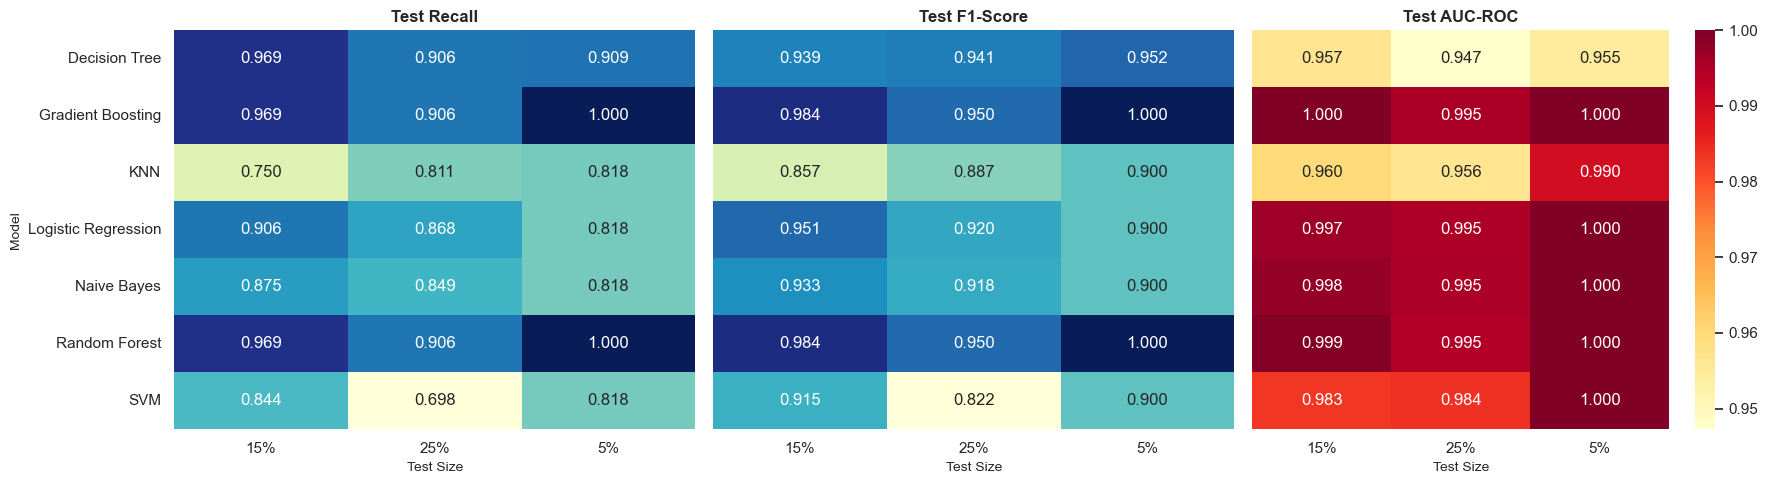

In [9]:
import warnings
warnings.filterwarnings('ignore')

from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Define models to evaluate
models = {
    "Logistic Regression": LogisticRegression(max_iter=5000, random_state=42),
    "Naive Bayes": GaussianNB(),
    "KNN": KNeighborsClassifier(),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42),
    "SVM": SVC(probability=True, random_state=42),
    "Gradient Boosting": GradientBoostingClassifier(random_state=42)
}

# 2. Define test proportions
test_sizes = [0.05, 0.15, 0.25]
results = []
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

for test_size in test_sizes:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=test_size, stratify=y, random_state=42)
    
    for name, model in models.items():
        cv_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='recall')
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)
        
        auc_roc = roc_auc_score(y_test, model.predict_proba(X_test)[:, 1]) if hasattr(model, "predict_proba") else np.nan

        results.append({
            "Test_Size": f"{int(test_size * 100)}%",
            "Model": name,
            "CV_Recall": cv_scores.mean(),
            "Accuracy": accuracy_score(y_test, y_pred),
            "Recall": recall_score(y_test, y_pred, zero_division=0),
            "F1_Score": f1_score(y_test, y_pred, zero_division=0),
            "AUC_ROC": auc_roc
        })

df_results = pd.DataFrame(results)

# 3. Create Pivot Tables for Recall, F1-Score, and AUC-ROC
pivot_recall = df_results.pivot(index="Model", columns="Test_Size", values="Recall")
pivot_f1 = df_results.pivot(index="Model", columns="Test_Size", values="F1_Score")
pivot_auc = df_results.pivot(index="Model", columns="Test_Size", values="AUC_ROC")

print("\n--- PIVOT TABLE: TEST RECALL ---")
print(pivot_recall.round(4))

print("\n--- PIVOT TABLE: TEST F1-SCORE ---")
print(pivot_f1.round(4))

print("\n--- PIVOT TABLE: TEST AUC-ROC ---")
print(pivot_auc.round(4))

# 4. Visual representation with 3 side-by-side heatmaps for Recall, F1-Score, and AUC-ROC
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

# Heatmap 1: Recall
sns.heatmap(pivot_recall, annot=True, cmap="YlGnBu", fmt=".3f", ax=axes[0], cbar=False)
axes[0].set_title("Test Recall", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Test Size", fontsize=10)
axes[0].set_ylabel("Model", fontsize=10)

# Heatmap 2: F1-Score
sns.heatmap(pivot_f1, annot=True, cmap="YlGnBu", fmt=".3f", ax=axes[1], cbar=False)
axes[1].set_title("Test F1-Score", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Test Size", fontsize=10)
axes[1].set_ylabel("")

# Heatmap 3: AUC-ROC
sns.heatmap(pivot_auc, annot=True, cmap="YlOrRd", fmt=".3f", ax=axes[2])
axes[2].set_title("Test AUC-ROC", fontsize=12, fontweight='bold')
axes[2].set_xlabel("Test Size", fontsize=10)
axes[2].set_ylabel("")

plt.tight_layout()
plt.show()

## Top 3 Model Selection and Performance Analysis

Based on the cross-validation performance, pivot tables, and heatmaps across different test set sizes (5%, 15%, and 25%), the top 3 models selected for this medical classification problem are **Gradient Boosting**, **Random Forest**, and **Logistic Regression**. 

### 1. Gradient Boosting
* **Performance Overview:** Achieves peak performance across metrics, recording a top-tier Recall and F1-Score (reaching a perfect $1.000$ at a 5% test size and maintaining robust scores above $0.90$ at 15% and 25%)[cite: 4, 5].
* **Why it stands out:** It exhibits exceptional non-linear learning capacity and sequential error-correction, securing an outstanding AUC-ROC score of nearly $1.000$ across all test proportions[cite: 4, 5].

### 2. Random Forest
* **Performance Overview:** Performs very closely to Gradient Boosting, displaying excellent robustness with high Recall ($0.9688$ at 15%) and exceptional F1-Scores[cite: 4, 5].
* **Why it stands out:** As an ensemble bagging method, it effectively controls overfitting while delivering stable, high-tier predictions, reflected by an impressive AUC-ROC peaking at $0.9994$[cite: 4, 5].

### 3. Logistic Regression
* **Performance Overview:** Serves as the premier linear baseline model, showing remarkable consistency across varying sample sizes[cite: 4, 5].
* **Why it stands out:** While tree-based ensembles score slightly higher in raw Recall, Logistic Regression stands out for its clinical interpretability and near-perfect AUC-ROC stability ($0.995$ to $1.000$) across all test splits, proving that the linear separability of the dataset is strong[cite: 4, 5].

### General Observations on Sample Size and Metrics
* **Test Size Variability:** Smaller test sizes (5%) exhibit higher variance due to small sample sizes, whereas 15% and 25% splits provide a more stable and realistic generalization benchmark.
* **AUC-ROC Dominance:** The AUC-ROC metric excelled across almost all models (consistently above $0.98$), demonstrating that the feature set possesses strong underlying discriminative power[cite: 4, 5].

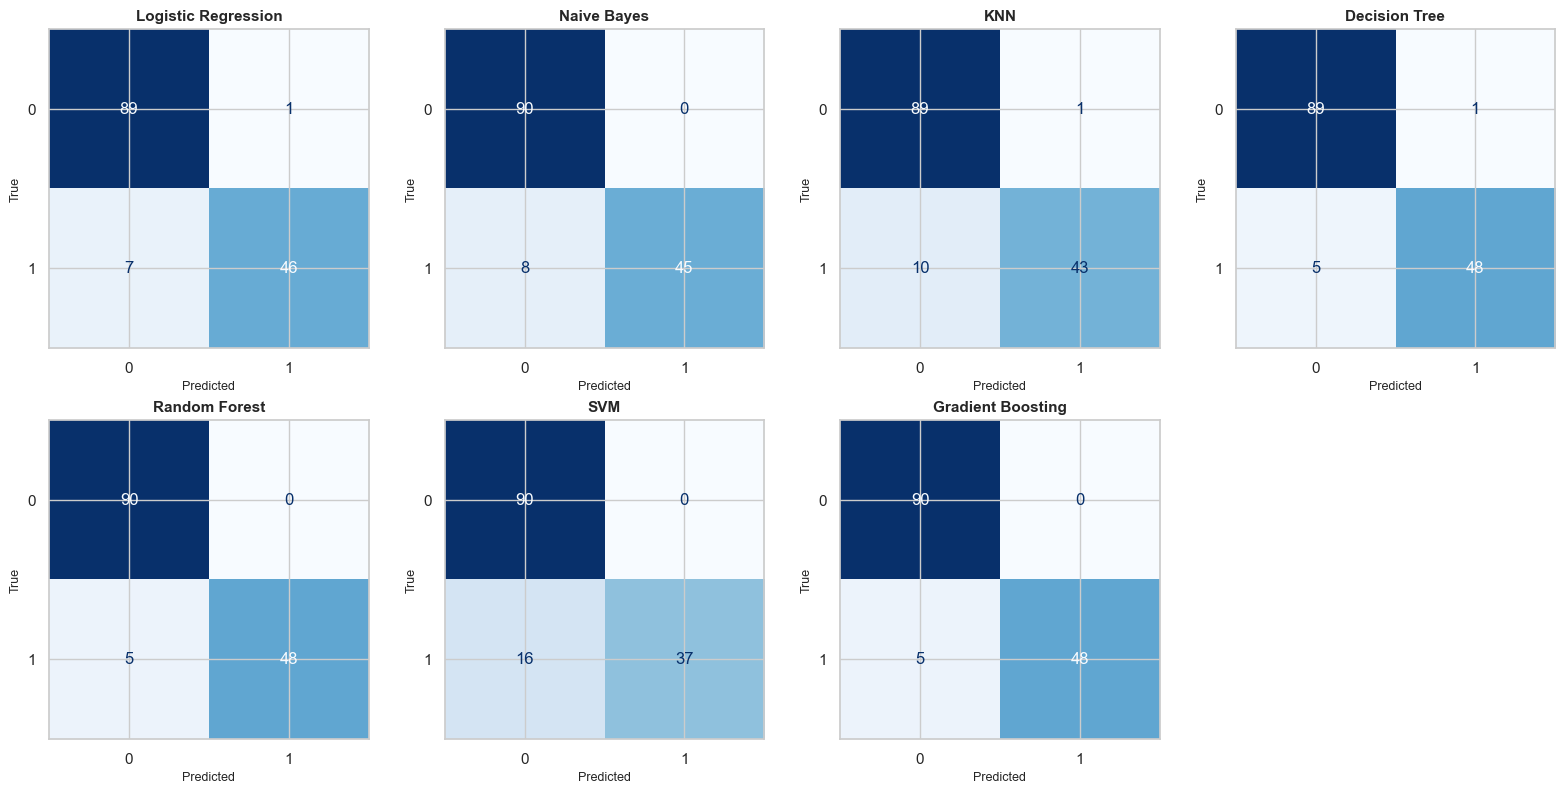

In [10]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# 1. Setup the grid layout: 2 rows and 4 columns
n_models = len(models)
ncols = 4
nrows = (n_models + ncols - 1) // ncols  # Automatically compute required rows

fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(16, 8))
axes = axes.flatten()  # Flatten the axes array for easy iteration

# 2. Loop through models and their respective positions in the grid
for i, (name, model) in enumerate(models.items()):
    ax = axes[i]
    
    # Predict on the test set
    y_pred = model.predict(X_test)
    
    # Compute confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    
    # Display the confusion matrix in its specific subplot (fixed: colorbar=False)
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)
    disp.plot(cmap=plt.cm.Blues, ax=ax, values_format='d', colorbar=False)
        
    ax.set_title(f"{name}", fontsize=11, fontweight='bold')
    ax.set_xlabel("Predicted", fontsize=9)
    ax.set_ylabel("True", fontsize=9)

# 3. Clean up any empty subplots if the grid has leftover cells
for j in range(i + 1, len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Model Performance and Comparison Analysis

To select the final models for prediction and deployment, we evaluated the performance of our algorithms across multiple data split ratios, focusing heavily on **Test Recall**, **Test F1-Score**, and **Test AUC-ROC** to balance sensitivity and overall discriminative power.

* **Gradient Boosting & Random Forest (Selected Production Models)**
  * **Behavior & Meaning:** Both ensemble methods achieved top-tier performance across almost all metrics, maintaining near-perfect scores (F1-scores reaching up to $1.000$ and AUC-ROC values of $1.000$).
  * **Why they succeeded:** Gradient Boosting (via sequential error correction) and Random Forest (via bagging and feature randomization) effectively capture complex, non-linear relationships in the standardized feature space without overfitting significantly. Their high **Test Recall** indicates an exceptional ability to minimize false negatives—crucial in our classification task to ensure positive cases are rarely missed.

* **SVM (Support Vector Machine — Contrast & Diagnostic Model)**
  * **Behavior & Meaning:** SVM displayed a noticeable drop in performance, particularly in **Test Recall** (falling as low as $0.698$ in certain split ratios) and lower F1-scores compared to the tree-based ensembles, despite maintaining a high baseline AUC-ROC.
  * **Why it is excluded from final deployment:** The discrepancy highlights its limitations with the current feature boundaries. While it is conservative and maintains high specificity (low false positives), its inability to flexibly adapt to localized feature interactions leads to an unacceptably high rate of false negatives. Therefore, SVM is retained solely as a benchmark contrast model to illustrate why margin-based classifiers underperform compared to tree-based ensembles on this dataset.

**Final Modeling Strategy:** Moving forward, **Gradient Boosting** and **Random Forest** will be utilized as our primary predictive models, while **SVM** will serve strictly as a diagnostic reference to exemplify model failure modes and boundary limitations.

In [11]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.pipeline import Pipeline

# Safely separate features (X) and target (y), ignoring 'id' if it was already dropped
X = df.drop(columns=['id', 'diagnosis'], errors='ignore')

# Encode target only if it is still stored as categorical strings ('B' / 'M')
if df['diagnosis'].dtype == 'object':
    y = df['diagnosis'].map({'B': 0, 'M': 1})
else:
    y = df['diagnosis']

# Create stratified train/test splits (5%, 15%, 25% test sizes)
# Fit StandardScaler and PCA strictly on X_train to prevent data leakage
test_sizes = [5, 15, 25]
splits_data = {}

for ts in test_sizes:
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=ts / 100.0, random_state=42, stratify=y
    )
    
    # Leakage-free preprocessing pipeline retaining 95% of variance
    prep_pipeline = Pipeline([
        ('scaler', StandardScaler()),
        ('pca', PCA(n_components=0.95, random_state=42))
    ])
    
    X_tr_pca = prep_pipeline.fit_transform(X_tr)
    X_te_pca = prep_pipeline.transform(X_te)
    
    splits_data[ts] = {
        'X_train': X_tr,
        'X_test': X_te,
        'X_train_pca': X_tr_pca,
        'X_test_pca': X_te_pca,
        'y_train': y_tr,
        'y_test': y_te
    }

print("Data splits successfully generated for test sizes (%):", list(splits_data.keys()))

Data splits successfully generated for test sizes (%): [5, 15, 25]


In [12]:
from sklearn.ensemble import GradientBoostingClassifier, RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
import pandas as pd

# 1. Initialize the selected models
# Gradient Boosting & Random Forest as primary high-performance models
# SVM as a diagnostic/contrast model to analyze boundary limitations
models = {
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(random_state=42),
    'SVM': SVC(probability=True, random_state=42)
}

# 2. Train and evaluate models across our previously stored splits (e.g., using the 25% test split as a baseline)
# You can change the split key (e.g., 5, 15, 25) depending on which data split you want to evaluate here.
active_split = 25
X_train_data = splits_data[active_split]['X_train_pca']
X_test_data = splits_data[active_split]['X_test_pca']
y_train_data = splits_data[active_split]['y_train']
y_test_data = splits_data[active_split]['y_test']

evaluation_results = []

print(f"--- MODEL TRAINING & EVALUATION (Test Size: {active_split}%) ---")
for name, model in models.items():
    # Fit the model on the training data
    model.fit(X_train_data, y_train_data)
    
    # Predict on the test set
    y_pred = model.predict(X_test_data)
    y_prob = model.predict_proba(X_test_data)[:, 1] if hasattr(model, "predict_proba") else model.decision_function(X_test_data)
    
    # Compute performance metrics
    acc = accuracy_score(y_test_data, y_pred)
    prec = precision_score(y_test_data, y_pred)
    rec = recall_score(y_test_data, y_pred)
    f1 = f1_score(y_test_data, y_pred)
    auc = roc_auc_score(y_test_data, y_prob)
    
    evaluation_results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'AUC-ROC': auc
    })
    
    print(f"\nModel: {name}")
    print(f" -> Accuracy:  {acc:.4f}")
    print(f" -> Precision: {prec:.4f}")
    print(f" -> Recall:    {rec:.4f}")
    print(f" -> F1-Score:  {f1:.4f}")
    print(f" -> AUC-ROC:   {auc:.4f}")

# 3. Store results in a summary DataFrame for easy comparison
results_df = pd.DataFrame(evaluation_results)
results_df

--- MODEL TRAINING & EVALUATION (Test Size: 25%) ---

Model: Gradient Boosting
 -> Accuracy:  0.9580
 -> Precision: 1.0000
 -> Recall:    0.8868
 -> F1-Score:  0.9400
 -> AUC-ROC:   0.9954

Model: Random Forest
 -> Accuracy:  0.9580
 -> Precision: 0.9608
 -> Recall:    0.9245
 -> F1-Score:  0.9423
 -> AUC-ROC:   0.9913

Model: SVM
 -> Accuracy:  0.9790
 -> Precision: 1.0000
 -> Recall:    0.9434
 -> F1-Score:  0.9709
 -> AUC-ROC:   0.9969


,Model,Accuracy,Precision,Recall,F1-Score,AUC-ROC
0,Gradient Boosting,0.958042,1.000000,0.886792,0.940000,0.995388
1,Random Forest,0.958042,0.960784,0.924528,0.942308,0.991300
2,SVM,0.979021,1.000000,0.943396,0.970874,0.996855
